# 02 · Compare monthly forecasts

**Question: does Ridge regression improve on simple monthly forecasts?** The target is national trade value in EUR: six countries × three categories × two directions = 36 series.

A planner could use these estimates as a starting point for expected trade activity. They are not forecasts of retail sales or stocks.

**This is a retrospective comparison on revised, already-inspected data.** I account for a publication delay, but cannot reconstruct the exact figures available historically.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from moto_study.forecasting import (
    CANDIDATES,
    SERIES,
    choose_candidate,
    development_experiments,
    final_comparison,
    make_features,
    metrics,
    paired_errors,
    predict_period,
)
from moto_study.io import load_prepared, project_root
from moto_study.plots import MODEL_LABELS, PRODUCT_LABELS, set_style, short_label
from moto_study.quality import monthly_totals

root = project_root()
monthly = monthly_totals(load_prepared(root, "country_totals"))
trade = load_prepared(root)
set_style()
pd.options.display.float_format = "{:,.3f}".format

## 1. Decide what could be known

At the **start** of month t, I allow inputs only through t−4. For January 2024, that means September 2023. This conservative scenario allows for detailed trade publication delays. [Timing source](../docs/DATA_SOURCES.md).

Inputs are the latest available month, the same month last year, and the last three available months' average. Sine and cosine encode the calendar so December sits next to January.

**Every fit and scaling step uses targets available by that cutoff.** Weights are refitted each month. This is a sequence of monthly forecasts, not two years predicted at once.

In [2]:
series = (
    monthly.loc[
        monthly.reporter.eq("BE") & monthly["product"].eq("87115000") & monthly.flow.eq("1")
    ]
    .set_index("month")
    .value_eur
)
x = make_features(series)
y = series.rename("target")
# Check relationships within one series, using only the initial training period.
training = x.join(y).loc[:"2021-09-01"].dropna()
display(training.corr(method="pearson").round(2))

,known_value,lag_12,known_3_mean,month_sin,month_cos,target
known_value,1.000,-0.120,0.790,-0.770,-0.160,-0.120
lag_12,-0.120,1.000,-0.330,0.400,-0.390,0.340
known_3_mean,0.790,-0.330,1.000,-0.800,0.200,-0.470
month_sin,-0.770,0.400,-0.800,1.000,0.060,0.360
month_cos,-0.160,-0.390,0.200,0.060,1.000,-0.580
target,-0.120,0.340,-0.470,0.360,-0.580,1.000


**Correlation helps identify overlapping inputs; it does not prove predictive value or causation.** This table concerns one series, not a mixture of countries. The average and latest value share information. Ridge restrains large weights when inputs overlap; chronological comparisons decide whether it helps.

In [3]:
month = pd.Timestamp("2024-01-01")
cutoff = month - pd.DateOffset(months=4)
fit = x.join(y).loc[:cutoff].dropna()
model = make_pipeline(StandardScaler(), Ridge(alpha=10))
model.fit(fit[x.columns], fit.target)
manual = max(float(model.predict(x.loc[[month]])[0]), 0)
example, audit = predict_period(
    monthly.loc[
        monthly.reporter.eq("BE") & monthly["product"].eq("87115000") & monthly.flow.eq("1")
    ],
    CANDIDATES["ridge_raw_seasonal_a10"],
    month,
    month,
)
assert np.isclose(manual, example.predicted_eur.iloc[0])
display(x.loc[[month]])
display(example[["month", "latest_input_month", "actual_eur", "predicted_eur"]])

,known_value,lag_12,known_3_mean,month_sin,month_cos
month,,,,,
2024-01-01,"40,640,308.000","36,290,395.000","42,346,202.000",0.500,0.866


,month,latest_input_month,actual_eur,predicted_eur
0,2024-01-01,2023-09-01,"13,772,066.000","34,662,233.210"


**The hand-worked prediction matches the reusable function.** Negative predictions are clipped to zero. Missing inputs are not filled with invented trade.

## 2. Compare a small set of candidates

- Two baselines: latest available value, and the same month last year.
- Three Ridge variants: raw values with/without seasonality, and log values with seasonality. The penalty stays at 10; this is not an exhaustive search.
- Development periods: 2022 and January–September 2023. Later 2023 targets would not yet be available before the January 2024 forecast. Choose the lowest mean period WAPE.

**WAPE = total absolute EUR error / total actual EUR. Lower is better.** It weights large flows more heavily and is not an accuracy percentage. The two development periods have different lengths; I give each equal weight.

In [4]:
development, development_audit = development_experiments(monthly)
selected, ranking = choose_candidate(development)
folds = metrics(development, ("model", "validation_year"))
display(folds.pivot(index="model", columns="validation_year", values="wape").mul(100).round(2))
display(
    ranking.assign(
        mean_validation_wape=ranking.mean_validation_wape * 100,
        worst_validation_wape=ranking.worst_validation_wape * 100,
    ).round(2)
)
assert (development_audit.latest_train_target <= development_audit.available_through).all()
display(
    Markdown(
        f"**{MODEL_LABELS[selected]} has the lowest development WAPE.** "
        "I retain it and both baselines with unchanged settings for the later comparison."
    )
)

validation_year,2022,2023
model,,
latest_known,39.680,42.430
ridge_log_seasonal_a10,31.470,29.410
ridge_raw_lags_a10,30.750,30.840
ridge_raw_seasonal_a10,31.010,26.770
seasonal_naive,32.280,31.150


,model,mean_validation_wape,worst_validation_wape
0,ridge_raw_seasonal_a10,28.890,31.010
1,ridge_log_seasonal_a10,30.440,31.470
2,ridge_raw_lags_a10,30.800,30.840
3,seasonal_naive,31.720,32.280
4,latest_known,41.060,42.430


**Ridge + season has the lowest development WAPE.** I retain it and both baselines with unchanged settings for the later comparison.

## 3. Check the later results and where they fail

MAE is the average absolute EUR miss per series-month. Bias is predicted minus observed value: negative means underprediction. All models use the same dates and information cutoff.

In [5]:
predictions, audit = final_comparison(monthly, selected)
assert (audit.latest_train_target <= audit.available_through).all()
results = metrics(predictions.assign(year=predictions.month.dt.year), ("model", "year"))
display(
    results.assign(
        WAPE_pct=results.wape * 100,
        MAE_million_EUR=results.mae_eur / 1e6,
        bias_million_EUR=results.bias_eur / 1e6,
    )[["model", "year", "n", "WAPE_pct", "MAE_million_EUR", "bias_million_EUR"]]
)
checks = []
for baseline in ["seasonal_naive", "latest_known"]:
    pairs = paired_errors(predictions, selected, baseline)
    per_series = pairs.groupby(SERIES)[
        ["baseline_absolute_error", "candidate_absolute_error"]
    ].sum()
    checks.append(
        {
            "baseline": MODEL_LABELS[baseline],
            "series with lower error": int(
                per_series.candidate_absolute_error.lt(per_series.baseline_absolute_error).sum()
            ),
            "series compared": len(per_series),
            "monthly wins (%)": 100
            * pairs.candidate_absolute_error.lt(pairs.baseline_absolute_error).mean(),
        }
    )
display(pd.DataFrame(checks))
seasonal_pairs = paired_errors(predictions, selected)
losses = seasonal_pairs.groupby(SERIES)[
    ["baseline_absolute_error", "candidate_absolute_error"]
].sum()
losses["extra_error_EUR"] = losses.candidate_absolute_error - losses.baseline_absolute_error
display(losses.nlargest(3, "extra_error_EUR").reset_index().replace({"product": PRODUCT_LABELS}))
predictions.to_parquet(root / "data/processed/forecast_predictions.parquet", index=False)

,model,year,n,WAPE_pct,MAE_million_EUR,bias_million_EUR
0,latest_known,2024,432,47.125,9.499,-0.114
1,latest_known,2025,432,51.491,10.590,0.139
2,ridge_raw_seasonal_a10,2024,432,24.401,4.918,-0.410
3,ridge_raw_seasonal_a10,2025,432,25.905,5.328,-0.688
4,seasonal_naive,2024,432,25.629,5.166,0.316
5,seasonal_naive,2025,432,27.867,5.731,-0.410


,baseline,series with lower error,series compared,monthly wins (%)
0,Same month last year,23,36,53.704
1,Latest available month,36,36,73.032


,reporter,product,flow,baseline_absolute_error,candidate_absolute_error,extra_error_EUR
0,IT,Above 800 cc,2,"266,810,118.000","296,643,432.073","29,833,314.073"
1,FR,Above 800 cc,1,"193,678,528.000","219,100,875.863","25,422,347.863"
2,BE,500-800 cc,1,"80,676,074.000","94,537,388.619","13,861,314.619"


**Ridge's pooled WAPE is 24.40% / 25.90% in 2024 / 2025, versus 25.63% / 27.87% for last year's month. The improvement is modest, and only 23/36 series beat that baseline.** The average miss is still EUR 4.92m / 5.33m. I keep the seasonal baseline visible rather than calling Ridge universally better.

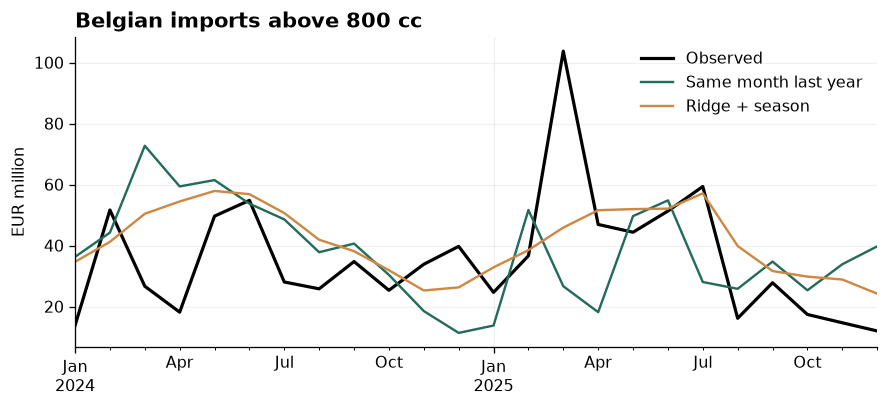

In [6]:
example_predictions = predictions.loc[
    predictions.reporter.eq("BE") & predictions["product"].eq("87115000") & predictions.flow.eq("1")
]
fig, ax = plt.subplots(figsize=(9, 3.5))
series.loc["2024":].div(1e6).plot(ax=ax, label="Observed", color="black", linewidth=2)
for name in ["seasonal_naive", selected]:
    values = (
        example_predictions.loc[example_predictions.model.eq(name)].set_index("month").predicted_eur
    )
    values.div(1e6).plot(ax=ax, label=MODEL_LABELS[name])
ax.set(title="Belgian imports above 800 cc", ylabel="EUR million", xlabel="")
ax.legend()
plt.show()

## 4. Investigate the March 2025 miss

A forecast miss is a reason to return to the data. I compare March with the same month a year earlier, then identify the partner contributions. These later facts explain the miss; they were not model inputs.

In [7]:
selected_row = example_predictions.loc[
    example_predictions.model.eq(selected) & example_predictions.month.eq("2025-03-01")
].iloc[0]
display(selected_row[["month", "actual_eur", "predicted_eur", "latest_input_month"]])
be = trade.loc[
    trade.reporter.eq("BE")
    & trade["product"].eq("87115000")
    & trade.flow.eq("1")
    & trade.month.isin(pd.to_datetime(["2024-03-01", "2025-03-01"]))
]
context = be.groupby("month")[["value_eur", "net_mass_kg"]].sum()
context["EUR/kg"] = context.value_eur / context.net_mass_kg
context["observed partners"] = be.groupby("month").partner.nunique()
display(context)
partner_change = be.pivot(index="partner_label", columns="month", values="value_eur")
partner_change["change_on_observed_pairs"] = partner_change.iloc[:, 1] - partner_change.iloc[:, 0]
display(partner_change.nlargest(4, "change_on_observed_pairs").rename(index=short_label))

month                 2025-03-01 00:00:00
actual_eur                103,753,227.000
predicted_eur              45,895,488.357
latest_input_month    2024-11-01 00:00:00
Name: 1838, dtype: object

,value_eur,net_mass_kg,EUR/kg,observed partners
month,,,,
2024-03-01,"26,661,733.000","577,162.000",46.195,10
2025-03-01,"103,753,227.000","2,823,136.000",36.751,13


month,2024-03-01 00:00:00,2025-03-01 00:00:00,change_on_observed_pairs
partner_label,,,
Thailand,"1,123,379.000","48,496,271.000","47,372,892.000"
United States,"3,971,476.000","37,620,320.000","33,648,844.000"
Netherlands,"2,103,553.000","3,705,103.000","1,601,550.000"
United Kingdom,"52,588.000","227,750.000","175,162.000"


**Thailand and the US drive the increase among observed partner pairs. More traded mass accompanies it; this is not simply a higher EUR/kg.** Item counts are not used to explain volume because notebook 01 found implausible quantities. Absent partner rows stay missing. The national target still includes unallocated trade.

**Decision: retain Ridge as a candidate and the seasonal forecast as the reference.** Neither anticipates every abrupt change. A fresh period with historical releases is needed before claiming operational value. Next: [prioritize unusual records](03_statistical_prioritization.ipynb).